# TweetEval – Offensive Language Detection
## Notebook 01 · Exploratory Data Analysis (EDA)

| | |
|---|---|
| **Course** | Machine Learning – CI1 – Faculté des Sciences de Bizerte |
| **Group members** | *Emna Ben Ali · Sirin Sandli · Youssef Abdennather · Adam Hamemi* |
| **Dataset chosen** | TweetEval – Offensive (binary: `offensive` / `non-offensive`) |
| **Task** | Predict whether a tweet is offensive |

---

### Contents
1. [Setup](#1)
2. [Loading the data](#2)
3. [Structure of the data](#3)
4. [Data quality checks](#4)
5. [Class distribution](#5)
6. [Text length analysis](#6)
7. [Stylistic / surface features](#7)
8. [Vocabulary analysis](#8)
9. [WordClouds per class](#9)
10. [Example tweets](#10)
11. [Conclusions & implications for preprocessing](#11)
12. [Saving the results](#12)

<a id="1"></a>
## 1. Setup
Imports, paths and a consistent colour scheme (blue = non-offensive, red = offensive).

In [33]:
import re, sys, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from wordcloud import WordCloud

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
MET_DIR = PROJECT_ROOT / "results" / "metrics"
for d in (RAW_DIR, FIG_DIR, MET_DIR):
    d.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {0: "non-offensive", 1: "offensive"}
COLORS = {"non-offensive": "#4C78A8", "offensive": "#E45756"}
PALETTE = [COLORS["non-offensive"], COLORS["offensive"]]

def savefig(fig, name):
    """Save a figure into results/figures/ and display it."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

print("Project root :", PROJECT_ROOT)
print("Raw data dir :", RAW_DIR)

Project root : c:\Users\ASUS\Desktop\TweetEval-offensiveML
Raw data dir : c:\Users\ASUS\Desktop\TweetEval-offensiveML\data\raw


<a id="2"></a>
## 2. Loading the data

The official TweetEval repository provides **six plain-text files** (one tweet / one label per line):

| Split | Files | Role in the project |
|---|---|---|
| train | `train_text.txt`, `train_labels.txt` | fit the vectorizer and the models |
| val | `val_text.txt`, `val_labels.txt` | model selection |
| test | `test_text.txt`, `test_labels.txt` | final evaluation **only** |

The cell below downloads the files into `data/raw/` if they are missing (raw files are never edited afterwards),
then loads them using `src/data_loader.py` (with an identical fallback if the module is not found).

In [34]:
import urllib.request

BASE_URL = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/offensive/"
FILES = [f"{s}_{k}.txt" for s in ("train", "val", "test") for k in ("text", "labels")]

for fname in FILES:
    target = RAW_DIR / fname
    if not target.exists():
        print("Downloading", fname)
        urllib.request.urlretrieve(BASE_URL + fname, target)

try:
    from src.data_loader import load_all
except ImportError:                    
    def _read_lines(path):
        with open(path, encoding="utf-8") as f:
            return [line.rstrip("\n") for line in f]

    def load_all(raw_dir=RAW_DIR):
        out = []
        for s in ("train", "val", "test"):
            texts = _read_lines(Path(raw_dir) / f"{s}_text.txt")
            labels = [int(x) for x in _read_lines(Path(raw_dir) / f"{s}_labels.txt")]
            assert len(texts) == len(labels), f"{s}: texts/labels mismatch"
            out.append(pd.DataFrame({"text": texts, "label": labels}))
        return tuple(out)

train_df, val_df, test_df = load_all()

# One combined frame (with a 'split' column) – handy for plots and comparisons
full_df = pd.concat(
    [train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")],
    ignore_index=True,
)
full_df["label_name"] = full_df["label"].map(LABEL_NAMES)
full_df["split"] = pd.Categorical(full_df["split"], ["train", "val", "test"], ordered=True)

print(f"train: {len(train_df):>6} tweets")
print(f"val  : {len(val_df):>6} tweets")
print(f"test : {len(test_df):>6} tweets")
print(f"total: {len(full_df):>6} tweets")

train:  11916 tweets
val  :   1324 tweets
test :    860 tweets
total:  14100 tweets


<a id="3"></a>
## 3. Structure of the data
`.head()`, `.info()` and `.describe()` as requested in the assignment.

In [35]:
print("=== HEAD (train) ===")
display(train_df.head(10))

=== HEAD (train) ===


,text,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become a Leader of your people instead or help and support your fellow countrymen.,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with his reads. He brought what has been missing. The deep ball presence. Now he just...,0
3,@user @user She is great. Hi Fiona!,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could be optic too Who know with Liberals They're all optics. No substance,1
5,"@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user This is the VetsResistSquadron"""" is Bullshit.. They are girl scout veterans, I have never met any other ve...",0
6,@user Your looking more like a plant #maga #walkaway,1
7,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer did and set America on the right path again. #MAGA,0
8,@user Been a Willie fan since before most of you were born....LOVE that he is holding a rally with Beto.... Exactly WHICH fans are furious? Could you give some specifics?,0
9,@user Here's a link to my channel with a plethora of topics to peruse:,0


In [36]:
print("=== INFO (train) ===")
train_df.info()
print("\n=== INFO (val) ===")
val_df.info()
print("\n=== INFO (test) ===")
test_df.info()

=== INFO (train) ===
<class 'pandas.DataFrame'>
RangeIndex: 11916 entries, 0 to 11915
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    11916 non-null  str  
 1   label   11916 non-null  int64
dtypes: int64(1), str(1)
memory usage: 186.3 KB

=== INFO (val) ===
<class 'pandas.DataFrame'>
RangeIndex: 1324 entries, 0 to 1323
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    1324 non-null   str  
 1   label   1324 non-null   int64
dtypes: int64(1), str(1)
memory usage: 20.8 KB

=== INFO (test) ===
<class 'pandas.DataFrame'>
RangeIndex: 860 entries, 0 to 859
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    860 non-null    str  
 1   label   860 non-null    int64
dtypes: int64(1), str(1)
memory usage: 13.6 KB


In [37]:
print("=== DESCRIBE – all columns (train) ===")
display(train_df.describe(include="all"))

print("Unique label values per split:")
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"  {name:5s} -> {sorted(d['label'].unique())}")

=== DESCRIBE – all columns (train) ===


,text,label
count,11916,11916.000000
unique,11883,NaN
top,@user Looks Like The Jokes On Liberals Again. #FortTrump #Poland #BoomingEconomy,NaN
freq,5,NaN
mean,NaN,0.330732
std,NaN,0.470496
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,0.000000
75%,NaN,1.000000


Unique label values per split:
  train -> [np.int64(0), np.int64(1)]
  val   -> [np.int64(0), np.int64(1)]
  test  -> [np.int64(0), np.int64(1)]


**Reading guide.** The dataset has only two columns: `text` (a string) and `label` (0 = non-offensive, 1 = offensive).
Since there are no numerical features, `describe()` is only informative for `label` – its mean is the proportion of offensive
tweets. Richer numerical descriptors (length, punctuation, …) are built in sections 6 and 7.

<a id="4"></a>
## 4. Data quality checks
Before modelling we verify: missing values, empty texts, duplicates, and — most importantly — **overlap between splits**
(identical tweets in train and test would inflate the final score = data leakage).

In [38]:
quality = []
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    quality.append({
        "split": name,
        "n_rows": len(d),
        "missing_text": d["text"].isna().sum(),
        "missing_label": d["label"].isna().sum(),
        "empty_text": (d["text"].str.strip() == "").sum(),
        "duplicate_texts": d["text"].duplicated().sum(),
        "duplicate_%": round(100 * d["text"].duplicated().mean(), 2),
    })
quality_df = pd.DataFrame(quality).set_index("split")
display(quality_df)

,n_rows,missing_text,missing_label,empty_text,duplicate_texts,duplicate_%
split,,,,,,
train,11916,0,0,0,33,0.28
val,1324,0,0,0,1,0.08
test,860,0,0,0,11,1.28


In [39]:
# --- Overlap between splits
tr, va, te = set(train_df["text"]), set(val_df["text"]), set(test_df["text"])
print("Identical tweets  train ∩ val :", len(tr & va))
print("Identical tweets  train ∩ test:", len(tr & te))
print("Identical tweets  val   ∩ test:", len(va & te))

# --- Duplicated tweets with CONFLICTING labels inside train
grp = train_df.groupby("text")["label"].nunique()
print("\nTweets appearing with both labels in train:", int((grp > 1).sum()))

Identical tweets  train ∩ val : 4
Identical tweets  train ∩ test: 4
Identical tweets  val   ∩ test: 0

Tweets appearing with both labels in train: 6


**Interpretation.** No missing or empty texts. Duplicates are few (33 in train, 11 in test ≈ 1.3 %), 4 tweets are shared between train and val and
4 between train and test, and 6 train tweets appear with both labels: all negligible, so the raw data is left untouched (we only mention it in the report).

<a id="5"></a>
## 5. Class distribution
Is the dataset balanced? This drives the choice of metrics: with an imbalanced dataset, **accuracy alone is misleading**
and precision / recall / F1 of the *offensive* class matter more.

In [40]:
counts = (full_df.groupby(["split", "label_name"]).size().unstack(fill_value=0))[["non-offensive", "offensive"]]
counts["total"] = counts.sum(axis=1)
counts["% offensive"] = (100 * counts["offensive"] / counts["total"]).round(2)
counts["% non-offensive"] = (100 - counts["% offensive"]).round(2)
display(counts)

maj = counts.loc["train", "non-offensive"] / counts.loc["train", "total"]
print(f"\nMajority-class baseline on train = {maj:.3f}  (a model that always predicts 'non-offensive')")
print(f"Imbalance ratio on train (non-off / off) = {counts.loc['train','non-offensive']/counts.loc['train','offensive']:.2f} : 1")

label_name,non-offensive,offensive,total,% offensive,% non-offensive
split,,,,,
train,7975,3941,11916,33.07,66.93
val,865,459,1324,34.67,65.33
test,620,240,860,27.91,72.09



Majority-class baseline on train = 0.669  (a model that always predicts 'non-offensive')
Imbalance ratio on train (non-off / off) = 2.02 : 1


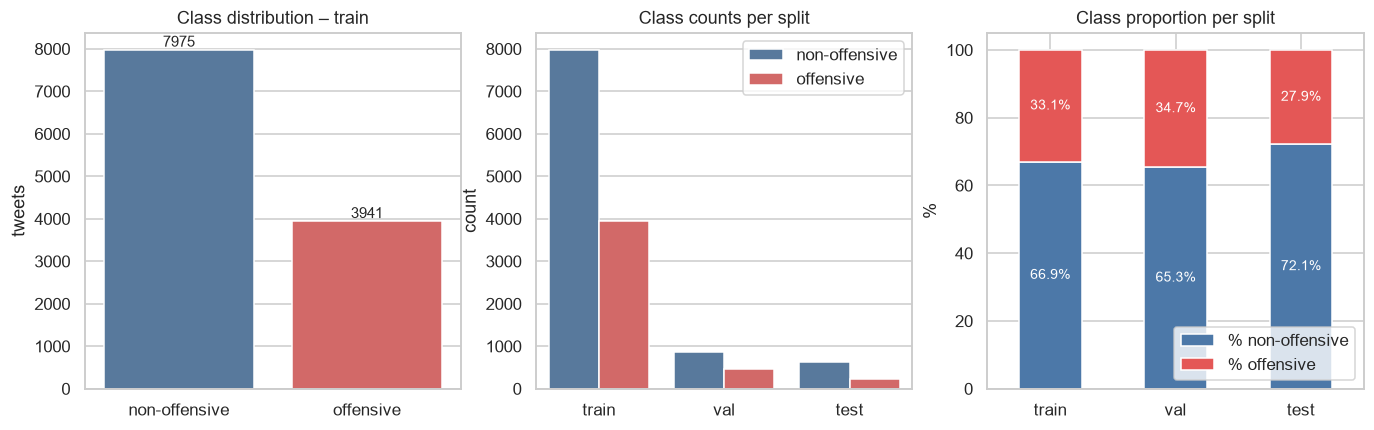

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) Train class counts
ax = axes[0]
sns.countplot(x="label_name", data=full_df[full_df.split == "train"],
              order=["non-offensive", "offensive"], palette=COLORS, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Class distribution – train"); ax.set_xlabel(""); ax.set_ylabel("tweets")

# (b) Counts per split
ax = axes[1]
sns.countplot(x="split", hue="label_name", data=full_df, hue_order=["non-offensive", "offensive"],
              palette=COLORS, ax=ax)
ax.set_title("Class counts per split"); ax.set_xlabel(""); ax.legend(title="")

# (c) Proportion per split
ax = axes[2]
prop = counts[["% non-offensive", "% offensive"]]
prop.plot(kind="bar", stacked=True, color=PALETTE, ax=ax, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", label_type="center", color="white", fontsize=9)
ax.set_title("Class proportion per split"); ax.set_xlabel(""); ax.set_ylabel("%"); ax.legend(title="", loc="lower right")
fig.savefig(
    FIG_DIR / "eda" / "01_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

**Observations.**
- The corpus is **moderately imbalanced**: 33.1 % of train, 34.7 % of val and 27.9 % of test tweets are offensive. Accuracy of a trivial majority-class model is
  therefore already high (~0.67), so models must be judged on **F1 / recall of the offensive class**, not only accuracy.
- The proportion of offensive tweets is **not identical across splits** (the official test set has fewer offensive tweets: 27.9 % vs ~33–35 %).
  This *distribution shift* is expected and explains why test scores may differ slightly from validation scores.

<a id="6"></a>
## 6. Text length analysis
Number of **characters** and number of **words** per tweet, overall and per class.

In [42]:
full_df["n_chars"] = full_df["text"].str.len()
full_df["n_words"] = full_df["text"].str.split().str.len()

train_len = full_df[full_df.split == "train"]
print("=== Global statistics (train) ===")
display(train_len[["n_chars", "n_words"]].describe().round(2))

print("=== Statistics per class (train) ===")
display(train_len.groupby("label_name")[["n_chars", "n_words"]].describe().round(2).T)

print("=== Statistics per split (all tweets) ===")
display(full_df.groupby("split")[["n_chars", "n_words"]].mean().round(2))

=== Global statistics (train) ===


,n_chars,n_words
count,11916.00,11916.00
mean,125.76,22.02
std,86.46,15.05
min,8.00,2.00
25%,54.00,10.00
50%,102.00,18.00
75%,184.00,32.00
max,581.00,103.00


=== Statistics per class (train) ===


label_name     non-offensive  offensive
n_chars count        7975.00    3941.00
        mean          122.76     131.84
        std            86.33      86.42
        min             8.00      11.00
        25%            53.00      59.00
        50%            98.00     112.00
        75%           178.00     196.00
        max           577.00     581.00
n_words count        7975.00    3941.00
        mean           21.41      23.26
        std            14.98      15.12
        min             2.00       2.00
        25%             9.00      11.00
        50%            17.00      20.00
        75%            31.00      34.00
        max           103.00     101.00

=== Statistics per split (all tweets) ===


,n_chars,n_words
split,,
train,125.76,22.02
val,132.83,23.34
test,144.74,23.75


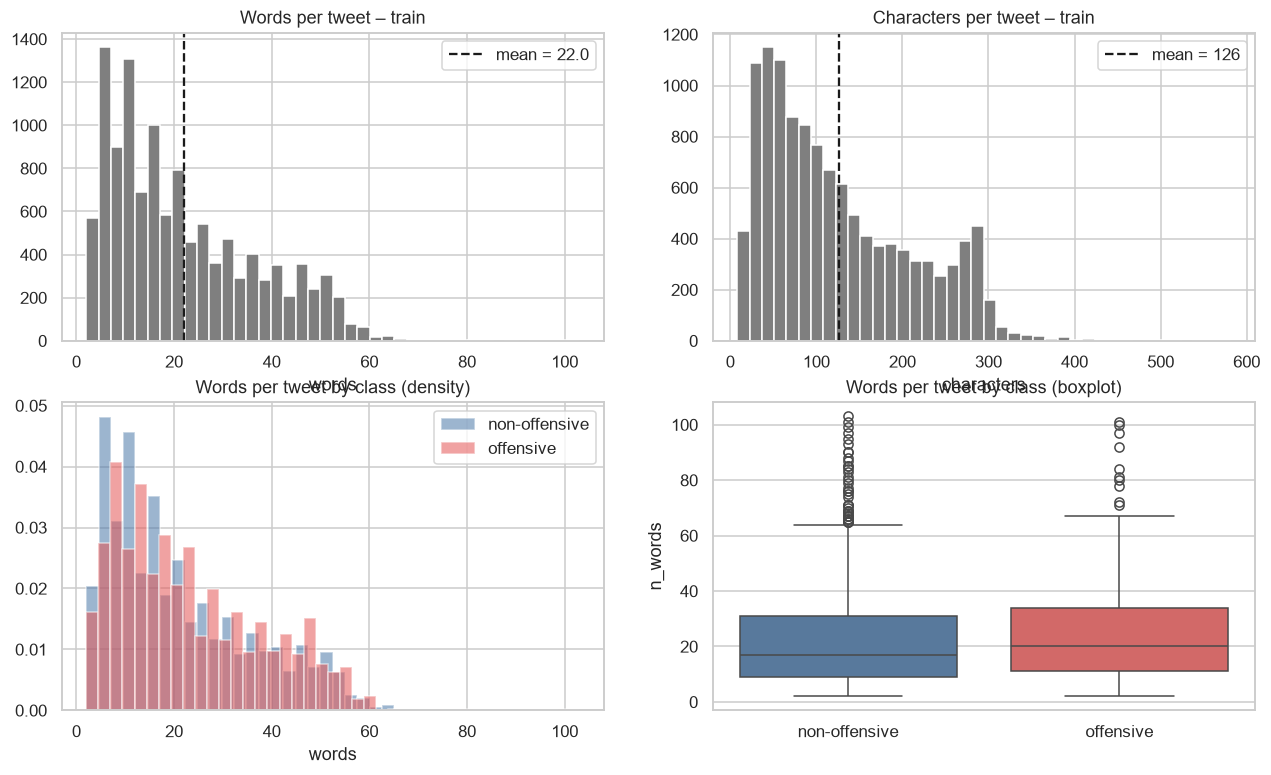

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Histograms (overall)
axes[0, 0].hist(train_len["n_words"], bins=40, color="#7f7f7f", edgecolor="white")
axes[0, 0].axvline(train_len["n_words"].mean(), color="k", ls="--", label=f"mean = {train_len['n_words'].mean():.1f}")
axes[0, 0].set_title("Words per tweet – train"); axes[0, 0].set_xlabel("words"); axes[0, 0].legend()

axes[0, 1].hist(train_len["n_chars"], bins=40, color="#7f7f7f", edgecolor="white")
axes[0, 1].axvline(train_len["n_chars"].mean(), color="k", ls="--", label=f"mean = {train_len['n_chars'].mean():.0f}")
axes[0, 1].set_title("Characters per tweet – train"); axes[0, 1].set_xlabel("characters"); axes[0, 1].legend()

# Per class (density so that classes of different size are comparable)
for lab in ["non-offensive", "offensive"]:
    sub = train_len[train_len.label_name == lab]
    axes[1, 0].hist(sub["n_words"], bins=40, alpha=0.55, density=True, color=COLORS[lab], label=lab)
axes[1, 0].set_title("Words per tweet by class (density)"); axes[1, 0].set_xlabel("words"); axes[1, 0].legend()

sns.boxplot(x="label_name", y="n_words", data=train_len, order=["non-offensive", "offensive"],
            palette=COLORS, ax=axes[1, 1])
axes[1, 1].set_title("Words per tweet by class (boxplot)"); axes[1, 1].set_xlabel("")

fig.savefig(
    FIG_DIR / "eda" / "02_length_histograms.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

In [44]:
# Is the length difference between the classes statistically significant?
a = train_len.loc[train_len.label == 0, "n_words"]
b = train_len.loc[train_len.label == 1, "n_words"]
stat, p = mannwhitneyu(a, b)
print(f"Median words – non-offensive: {a.median():.0f} | offensive: {b.median():.0f}")
print(f"Mann-Whitney U test: U = {stat:.0f}, p-value = {p:.2e}")
print("-> difference is", "statistically significant" if p < 0.05 else "NOT statistically significant", "(alpha = 0.05)")

Median words – non-offensive: 17 | offensive: 20
Mann-Whitney U test: U = 14464391, p-value = 1.44e-12
-> difference is statistically significant (alpha = 0.05)


**Observations.**
- Tweets are **short** (a few dozen words at most, limited by the platform), so the bag-of-words matrix will be **very sparse**.
- Offensive tweets are slightly longer (median 20 vs 17 words). The Mann-Whitney test is significant because the sample is large, but the
  distributions overlap heavily: **the effect is small, so length alone is not a useful discriminating feature** and the classifier must rely on the vocabulary.
- No extreme outliers need removal: very short tweets are valid and can still be offensive (e.g. a single insult).

<a id="7"></a>
## 7. Stylistic / surface features
The assignment asks us to justify cleaning choices (negations, stop-words, hashtags, capitals…). To do so we measure how
frequent each of these elements is **per class**: an element that behaves differently between classes carries information
and should perhaps **not** be removed.

In TweetEval, user mentions are already anonymised as `@user` (≈92 % of tweets contain one) and, as the check below confirms, **URLs have already been removed** from the text.

In [45]:
EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\U0001F000-\U0001F2FF]")
NEGATION_RE = re.compile(r"\b(?:not|no|never|none|nobody|nothing|neither|nor|can't|cant|won't|don't|dont|doesn't|didn't|isn't|aren't|wasn't|weren't|n't)\b|n't\b", re.I)

feat = pd.DataFrame({
    "mention":      full_df["text"].str.count(r"@\w+") > 0,
    "url":          full_df["text"].str.contains(r"http\S*|www\.", regex=True),
    "hashtag":      full_df["text"].str.contains(r"#\w+", regex=True),
    "emoji":        full_df["text"].apply(lambda t: bool(EMOJI_RE.search(t))),
    "exclamation !":full_df["text"].str.contains("!", regex=False),
    "question ?":   full_df["text"].str.contains("?", regex=False),
    "ALL-CAPS word":full_df["text"].apply(lambda t: any(w.isupper() and len(w) > 2 and w.isalpha() for w in t.split())),
    "elongation (sooo)": full_df["text"].str.contains(r"(\w)\1{2,}", regex=True),
    "negation":     full_df["text"].str.contains(NEGATION_RE),
    "profanity mask (* or ****)": full_df["text"].str.contains(r"\w\*+\w*|\*{2,}", regex=True),
})
feat["label_name"] = full_df["label_name"]
feat["split"] = full_df["split"]

train_feat = feat[feat.split == "train"]
pct = (train_feat.drop(columns=["split"]).groupby("label_name").mean().T * 100).round(1)
pct["difference (off − non-off)"] = (pct["offensive"] - pct["non-offensive"]).round(1)
pct = pct[["non-offensive", "offensive", "difference (off − non-off)"]]
print("% of tweets containing each element (train):")
display(pct.sort_values("difference (off − non-off)", ascending=False))

% of tweets containing each element (train):


label_name,non-offensive,offensive,difference (off − non-off)
negation,25.7,29.3,3.6
ALL-CAPS word,14.6,16.6,2.0
mention,92.2,94.1,1.9
exclamation !,18.4,19.4,1.0
elongation (sooo),2.1,2.7,0.6
profanity mask (* or ****),0.7,1.0,0.3
url,0.0,0.0,0.0
question ?,15.2,14.3,-0.9
hashtag,15.4,12.6,-2.8
emoji,12.2,9.3,-2.9


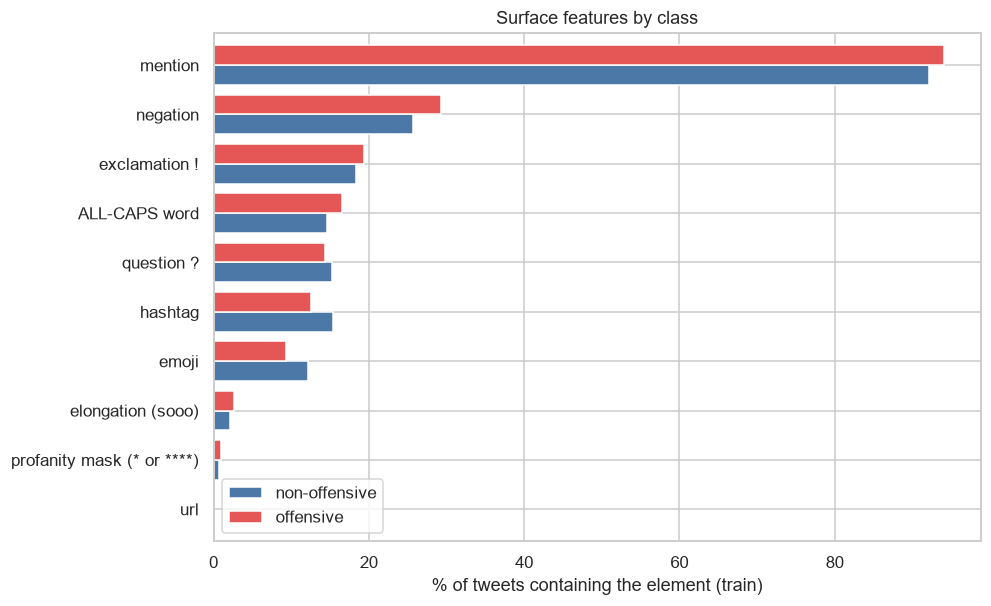

In [46]:
plot_df = pct[["non-offensive", "offensive"]].sort_values("offensive")
ax = plot_df.plot(kind="barh", color=PALETTE, figsize=(9, 6), width=0.8)
ax.set_xlabel("% of tweets containing the element (train)")
ax.set_title("Surface features by class")
ax.legend(title="")
# Save figure
fig.savefig(
    FIG_DIR / "eda" / "03_surface_features.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

In [47]:
# Average counts per tweet (train) for a few numeric descriptors
num = pd.DataFrame({
    "n_mentions":   full_df["text"].str.count(r"@\w+"),
    "n_hashtags":   full_df["text"].str.count(r"#\w+"),
    "n_exclam":     full_df["text"].str.count("!"),
    "n_question":   full_df["text"].str.count(r"\?"),
    "n_caps_words": full_df["text"].apply(lambda t: sum(w.isupper() and len(w) > 2 and w.isalpha() for w in t.split())),
    "upper_ratio":  full_df["text"].apply(lambda t: sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t))),
})
num["label_name"] = full_df["label_name"]; num["split"] = full_df["split"]
display(num[num.split == "train"].groupby("label_name").mean(numeric_only=True).round(3))

,n_mentions,n_hashtags,n_exclam,n_question,n_caps_words,upper_ratio
label_name,,,,,,
non-offensive,2.752,0.443,0.361,0.221,0.327,0.078
offensive,2.032,0.325,0.438,0.238,0.451,0.077


**Observations.** Differences between classes are small for most surface features (≤ 4 points). The largest are **negations** (29 % offensive vs 26 %) and ALL-CAPS words (+2 points); hashtags and emojis are slightly more common in non-offensive tweets. Masked profanity (`f***`) is rare (~1 %). These cues are weak individually, so we keep them (no aggressive cleaning) rather than rely on them.

**Implications for preprocessing.**

| Element | What we look for | Decision to take in notebook 02 |
|---|---|---|
| `@user` mentions | present in ~92–94 % of tweets in both classes → almost no discriminating power | keep as the single placeholder `@user` or drop it |
| URLs (`http`) | 0 % of tweets in this version of the dataset | nothing to remove, but keep the regex for robustness |
| Hashtags | may contain topical words | keep the **word** (remove only `#`) |
| ALL-CAPS, `!` | shouting is a typical aggression cue | lowercasing loses it → consider a feature or keep `!` |
| Negations (`not`, `don't`) | change polarity ("not stupid") | **do not** remove them with the stop-words |
| Profanity masks (`f***`) | offensive even when obfuscated | keep `*` patterns or normalise them |
| Elongations (`sooo`) | emphasis | optional normalisation |

<a id="8"></a>
## 8. Vocabulary analysis
Which words are the most frequent per class, and — more interesting — which words are **the most characteristic** of each class?

A minimal tokenizer (lowercase, alphabetic tokens) is used here for exploration only; the real cleaning is done in notebook 02.

In [48]:
STOP = set(ENGLISH_STOP_WORDS) | {"user", "http", "https", "amp", "rt", "im", "u"}
TOKEN_RE = re.compile(r"[a-z][a-z'\*]+")

def tokenize(text, remove_stop=True):
    toks = TOKEN_RE.findall(text.lower())
    toks = [t.strip("'") for t in toks]
    if remove_stop:
        toks = [t for t in toks if t not in STOP and len(t) > 2]
    return toks

train_only = full_df[full_df.split == "train"]
counter = {lab: Counter() for lab in (0, 1)}
for lab, txt in zip(train_only["label"], train_only["text"]):
    counter[lab].update(tokenize(txt))

print("Distinct tokens (after stop-word removal)  non-offensive:", len(counter[0]), "| offensive:", len(counter[1]))
print("Total tokens                               non-offensive:", sum(counter[0].values()), "| offensive:", sum(counter[1].values()))

all_vocab = set(counter[0]) | set(counter[1])
print("Vocabulary size (train):", len(all_vocab))
print("Words appearing only once:", sum(1 for w in all_vocab if counter[0][w] + counter[1][w] == 1),
      "  → justifies min_df=2 in the TF-IDF")

Distinct tokens (after stop-word removal)  non-offensive: 13699 | offensive: 9117
Total tokens                               non-offensive: 70245 | offensive: 40326
Vocabulary size (train): 17295
Words appearing only once: 9374   → justifies min_df=2 in the TF-IDF


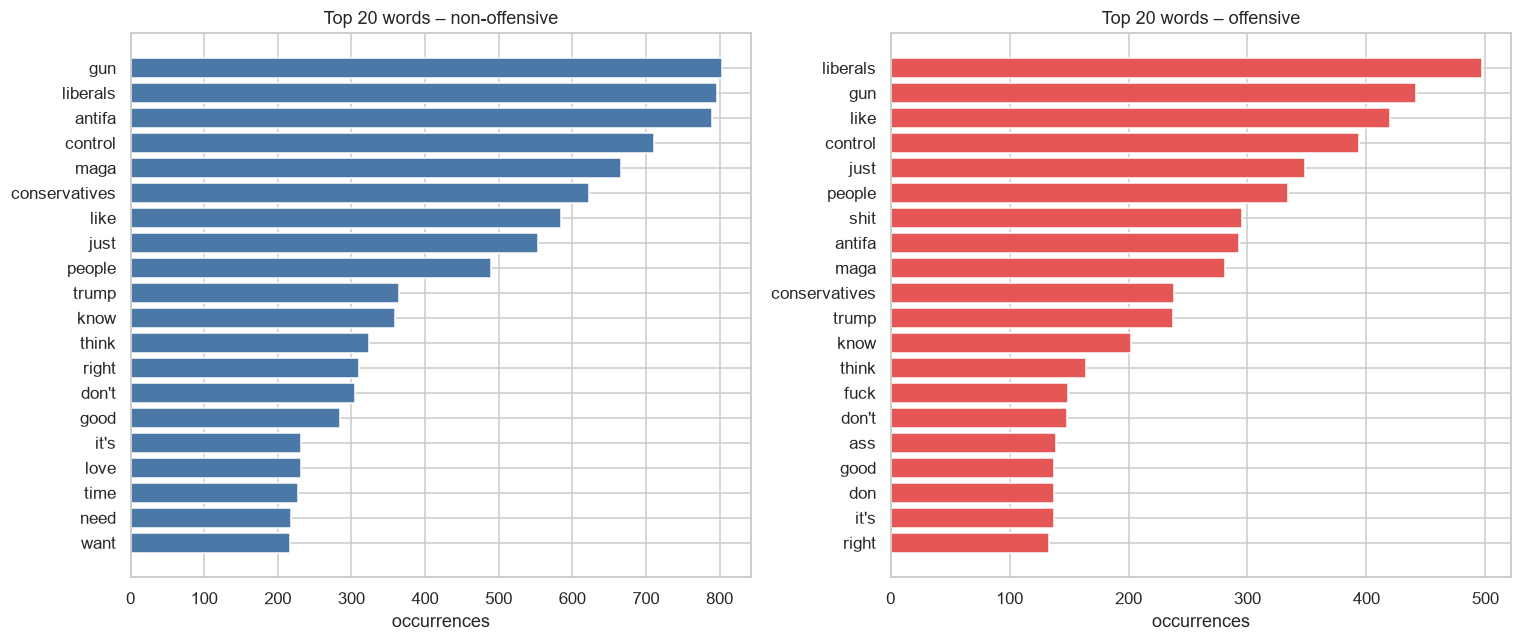

In [49]:
# Top-20 most frequent words per class
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, lab in zip(axes, (0, 1)):
    name = LABEL_NAMES[lab]
    words, vals = zip(*counter[lab].most_common(20))
    ax.barh(
        words[::-1],
        vals[::-1],
        color=COLORS[name]
    )
    ax.set_title(f"Top 20 words – {name}")
    ax.set_xlabel("occurrences")
fig.tight_layout()
# Save figure
fig.savefig(
    FIG_DIR / "eda" / "04_top_words_per_class.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

Raw frequency is dominated by words common to both classes. A more informative measure is the **smoothed log-odds ratio**:

$$\text{score}(w) = \log\frac{(c_{off}(w)+1)/(N_{off}+V)}{(c_{non}(w)+1)/(N_{non}+V)}$$

A large positive score → the word is characteristic of the offensive class; a large negative score → of the non-offensive class.
Only words with at least 15 occurrences are kept to avoid noise.

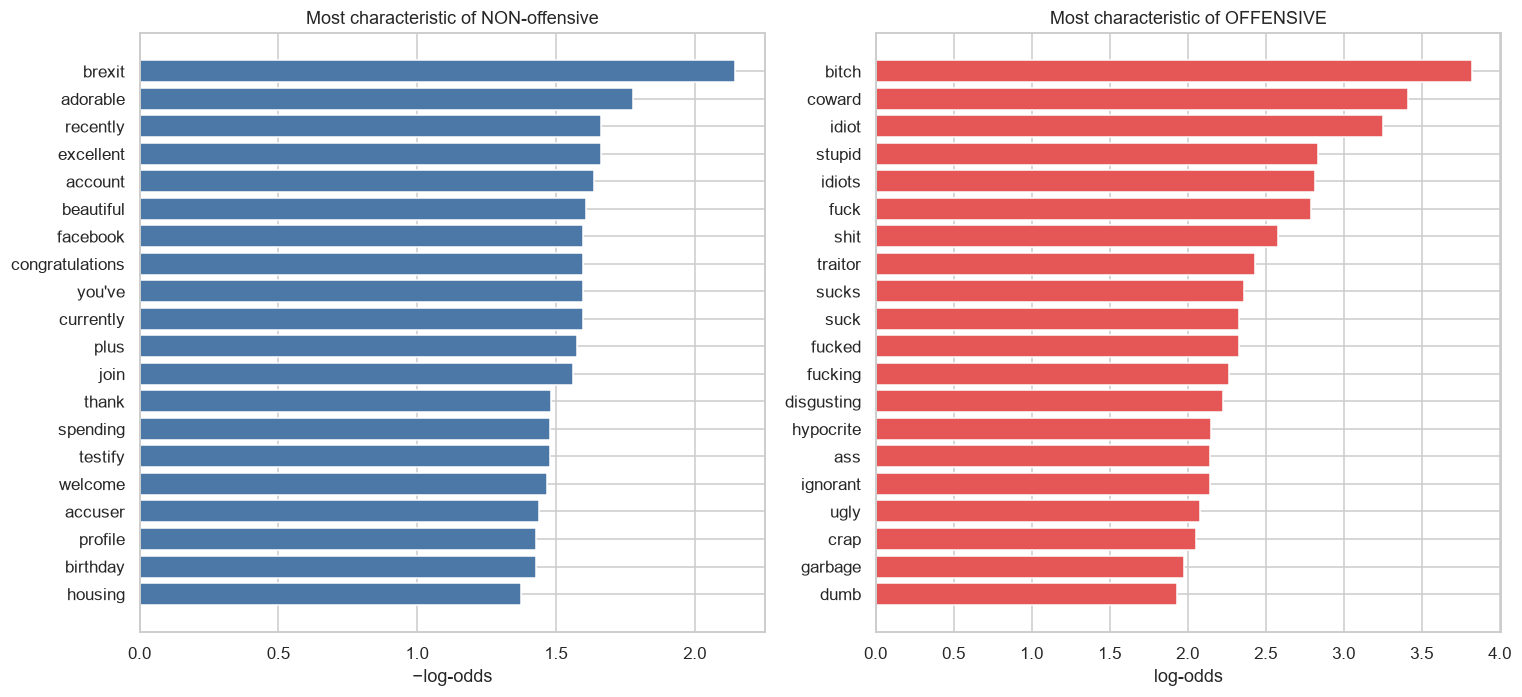

Top discriminative OFFENSIVE words (with counts):


,word,count_non_off,count_off,log_odds
0,bitch,2,89,3.82
1,coward,0,19,3.41
2,idiot,2,50,3.25
3,stupid,8,100,2.84
4,idiots,1,21,2.82
5,fuck,13,149,2.79
6,shit,33,295,2.58
7,traitor,1,14,2.43
8,sucks,5,41,2.36
9,suck,3,26,2.33


In [50]:
V = len(all_vocab)
N0, N1 = sum(counter[0].values()), sum(counter[1].values())
rows = []
for w in all_vocab:
    c0, c1 = counter[0][w], counter[1][w]

    if c0 + c1 >= 15:
        score = (
            np.log((c1 + 1) / (N1 + V))
            - np.log((c0 + 1) / (N0 + V))
        )
        rows.append((w, c0, c1, score))
lo = pd.DataFrame(
    rows,
    columns=["word", "count_non_off", "count_off", "log_odds"]
).sort_values("log_odds")
top_off = lo.tail(20).iloc[::-1]
top_non = lo.head(20)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
axes[0].barh(
    top_non["word"][::-1],
    -top_non["log_odds"][::-1],
    color=COLORS["non-offensive"]
)
axes[0].set_title("Most characteristic of NON-offensive")
axes[0].set_xlabel("−log-odds")
axes[1].barh(
    top_off["word"][::-1],
    top_off["log_odds"][::-1],
    color=COLORS["offensive"]
)
axes[1].set_title("Most characteristic of OFFENSIVE")
axes[1].set_xlabel("log-odds")
fig.tight_layout()
# Save figure in results/figures/eda/
fig.savefig(
    FIG_DIR / "eda" / "05_discriminative_words.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)
print("Top discriminative OFFENSIVE words (with counts):")
display(top_off.head(10).round(2).reset_index(drop=True))

**Observations.**
- The **offensive** class is characterised by insults and profanity (`bitch`, `idiot`, `stupid`, `fuck`, `shit`, `coward`…), which is why a lexical model (TF-IDF + linear classifier) should work
  reasonably well.
- The **non-offensive** class is characterised by neutral / positive or topical vocabulary (`beautiful`, `congratulations`, `excellent`, `brexit`…).
- About 54 % of the 17 295 training tokens appear only once → the vocabulary has a long tail; `min_df=2` and `max_features` in TF-IDF reduce noise and dimensionality.
- Offensiveness is sometimes **contextual** (sarcasm, implicit insults) and cannot be captured by single words: this limits
  bag-of-words models and motivates `ngram_range=(1, 2)`.

<a id="9"></a>
## 9. WordClouds per class
Word size is proportional to frequency (stop-words, `@user` and `http` removed).

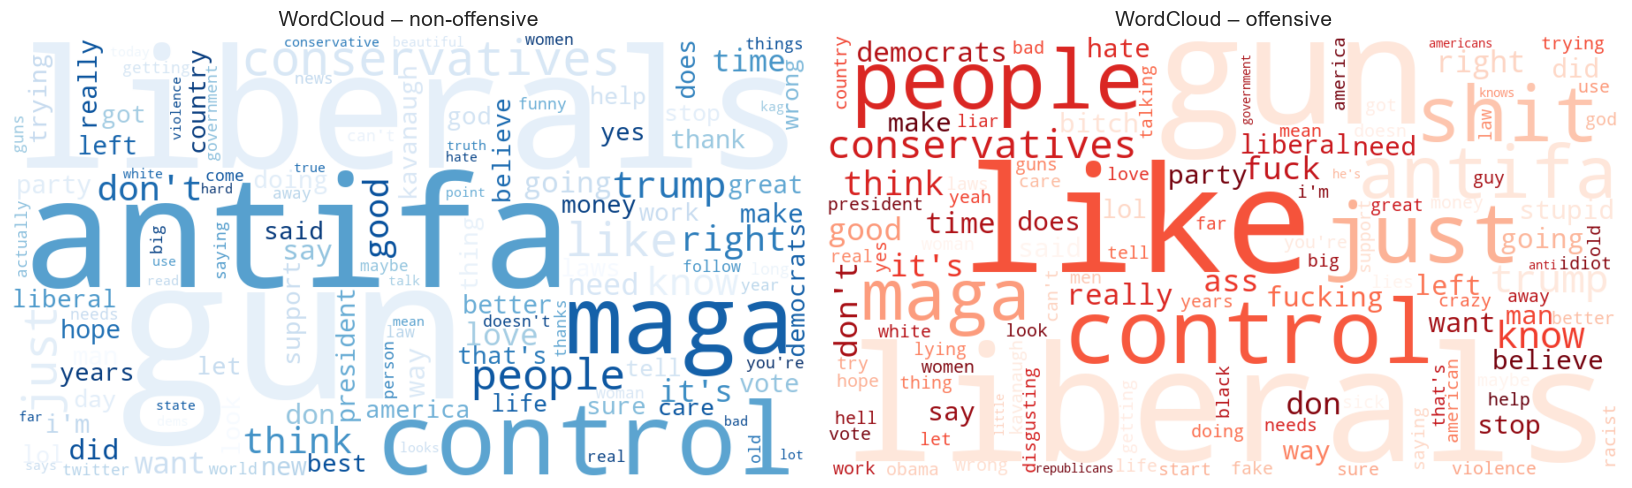

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cmaps = {0: "Blues", 1: "Reds"}
for ax, lab in zip(axes, (0, 1)):
    wc = WordCloud(width=900, height=500, background_color="white", colormap=cmaps[lab],
                   max_words=120, random_state=42).generate_from_frequencies(counter[lab])
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"WordCloud – {LABEL_NAMES[lab]}", fontsize=14)
fig.tight_layout()
fig.savefig(
    FIG_DIR / "eda" / "06_wordclouds.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

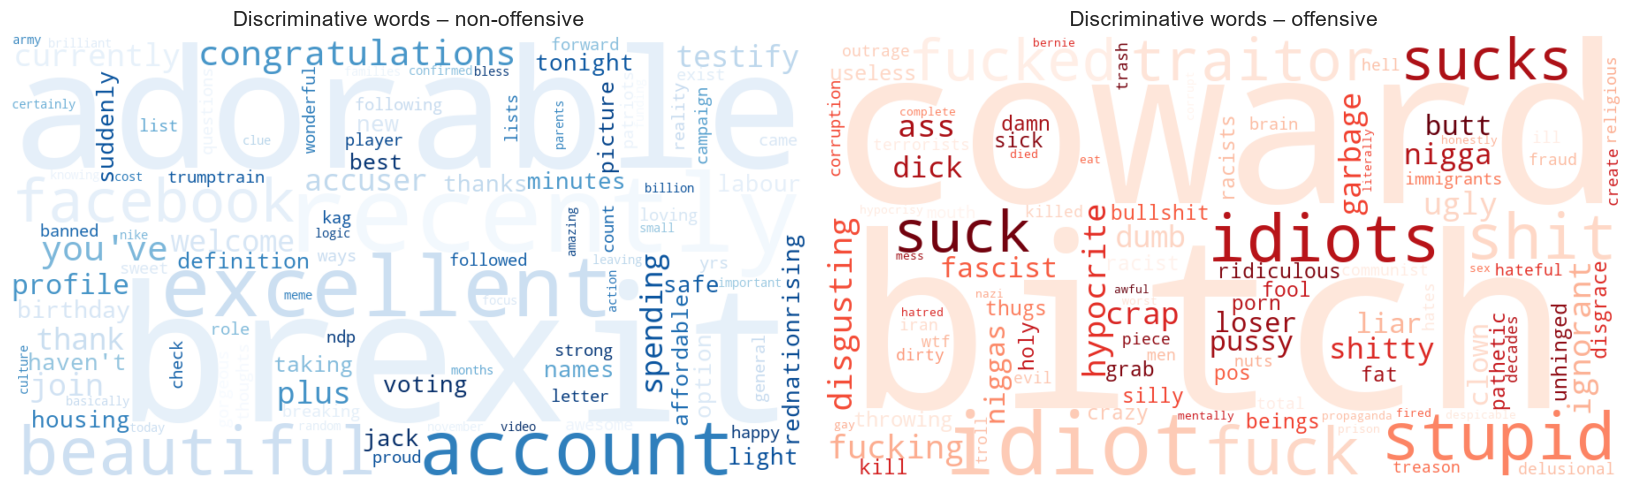

In [52]:
# WordCloud of the *discriminative* words (log-odds) – removes words shared by both classes
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pos = lo[lo.log_odds > 0].set_index("word")["log_odds"].to_dict()
neg = {w: -s for w, s in lo[lo.log_odds < 0].set_index("word")["log_odds"].to_dict().items()}
for ax, freqs, lab in zip(axes, (neg, pos), (0, 1)):
    wc = WordCloud(width=900, height=500, background_color="white", colormap=cmaps[lab],
                   max_words=100, random_state=42).generate_from_frequencies(freqs)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"Discriminative words – {LABEL_NAMES[lab]}", fontsize=14)
fig.tight_layout()
fig.savefig(
    FIG_DIR / "eda" / "07_wordclouds_discriminative.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

**Note.** The first pair of clouds is based on frequency and shows what people talk about; the second pair is based on the log-odds score
and highlights what **distinguishes** the classes — it is the more relevant one for classification. *Content warning: the offensive cloud
contains vulgar words.*

<a id="10"></a>
## 10. Example tweets
Reading real examples helps to spot difficulties that statistics cannot show (sarcasm, quoted insults, missing context).

In [53]:
pd.set_option("display.max_colwidth", 200)
print("=== 8 random NON-offensive tweets ===")
display(train_df[train_df.label == 0].sample(8, random_state=1)[["text"]].reset_index(drop=True))
print("=== 8 random OFFENSIVE tweets (content warning) ===")
display(train_df[train_df.label == 1].sample(8, random_state=1)[["text"]].reset_index(drop=True))

=== 8 random NON-offensive tweets ===


,text
0,@user What??? She is cute but she doesn't look like me at all
1,@user @user Thank you @user
2,#MAGA Sing like no one is listening Love like you've never been hurt Vote GOP when no one is watching And don't listen to Liberals' dirt
3,Remind me again why exactly there's a lingerie store next to a krav maga dojo
4,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...
5,@user She is!!! 😍
6,@user @user so you say. When you are older you may understand. What anyone believes is quite irrelevant--as you yourself are asserting.
7,@user And god forbid you are already talking to someone or dating they get real mad 😂🤷🏼‍♀️ we like those people over you for a reason sorry bout it 😂


=== 8 random OFFENSIVE tweets (content warning) ===


,text
0,@user So has the Law changed...you just make an allegation now days and your guilty until proven innocent. Liberals are mentally ill!
1,@user @user @user For the love of all things sacred he cannot be voted in. He is well down towrds the bottom of that scummy swamp. The Scales of Justice need to let him drown in his own shit. Make...
2,@user THE DEVIL MADE ME DO IT!!!!! THE UGLY FACE OF LIBERALS! I FEEL SORRY FOR THE INNOCENT HONEST ONES THAT ARE JUST BRAINWASHED!
3,@user State Sponsored Kids Protesting the 2nd Amendment? Youth invasion of D.C. took place as young fascists-in-training were corralled into D.C. to demand that govt strip away the liberties of ...
4,@user Wtf aren’t they treating antifa as terrorism?
5,Really # MAGA VOTE TRUMP 2020
6,@user Cuz liberals are sick of cnn!!!!
7,"@user @user @user This is fun, I asked him for proof and he blocked me. I was about to joke about how he'd go from The Antifa are the real Nazis!"""" to similar alt-shite talking points, boy that su..."


In [54]:
# Shortest and longest tweets
tl = full_df[full_df.split == "train"].sort_values("n_words")
print("=== 5 shortest tweets ===")
display(tl.head(5)[["text", "label_name", "n_words"]].reset_index(drop=True))
print("=== 5 longest tweets ===")
display(tl.tail(5)[["text", "label_name", "n_words"]].reset_index(drop=True))

=== 5 shortest tweets ===


,text,label_name,n_words
0,@user well...?,non-offensive,2
1,@user Fool,offensive,2
2,@user Horrible.,offensive,2
3,@user Boycott,non-offensive,2
4,@user Sucks,offensive,2


=== 5 longest tweets ===


,text,label_name,n_words
0,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,non-offensive,99
1,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,offensive,100
2,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,offensive,101
3,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,non-offensive,101
4,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,non-offensive,103


<a id="11"></a>
## 11. Conclusions & implications for preprocessing

### Key findings
| # | Finding | Consequence |
|---|---|---|
| 1 | Two clean columns (`text`, `label`), no missing values, official train / val / test splits | no imputation; use the official splits as-is |
| 2 | **Moderate class imbalance** (~1/3 offensive in train, different share in test) | report precision, recall and **F1 of the offensive class**, not only accuracy; consider `class_weight='balanced'` |
| 3 | Tweets are short with a heavy-tailed vocabulary | sparse TF-IDF, `min_df=2`, `max_features≈20 000` |
| 4 | Mentions are anonymised (`@user`, ~93 % of tweets, same rate in both classes); URLs are already absent | no real signal → normalise or drop `@user` |
| 5 | Offensive tweets are strongly marked by profanity / insult words | lexical features (TF-IDF unigrams + bigrams) are appropriate |
| 6 | Negations, `!`, capitals, masked profanity (`f***`) may carry information | **do not** blindly remove all stop-words, keep negations and `*` patterns |
| 7 | Some offensiveness is contextual / sarcastic | expected ceiling for bag-of-words models; BERT-type models are a possible extension |


<a id="12"></a>
## 12. Saving the results
Summary statistics are stored in `results/metrics/` so they can be re-used in the report and the final notebook.
Figures were already saved in `results/figures/`.

In [55]:
# Save EDA metrics
summary = counts.copy()

summary["avg_words"] = full_df.groupby("split")["n_words"].mean().round(2)
summary["avg_chars"] = full_df.groupby("split")["n_chars"].mean().round(2)

summary.to_csv(MET_DIR / "eda" / "eda_summary.csv")
pct.to_csv(MET_DIR / "eda" / "eda_surface_features.csv")

lo.sort_values("log_odds").to_csv(
    MET_DIR / "eda" / "eda_discriminative_words.csv",
    index=False
)

quality_df.to_csv(
    MET_DIR / "eda" / "eda_quality_checks.csv",
    index=False
)

# Display saved files
print("Saved metrics:", sorted(
    p.name for p in (MET_DIR / "eda").glob("eda_*.csv")
))

print("Saved figures:", sorted(
    p.name for p in (FIG_DIR / "eda").glob("0*.png")
))

Saved metrics: ['eda_discriminative_words.csv', 'eda_quality_checks.csv', 'eda_summary.csv', 'eda_surface_features.csv']
Saved figures: ['01_class_distribution.png', '02_length_histograms.png', '03_surface_features.png', '04_top_words_per_class.png', '05_discriminative_words.png', '06_wordclouds.png', '07_wordclouds_discriminative.png']
